## Import library

In [1]:
import pandas as pd
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

## Baca dataset

In [2]:
DATA_PATH = Path("../data/raw/Child Dev.xlsx")

df = pd.read_excel(DATA_PATH)

print("Dataset berhasil dibaca.")
print("Ukuran dataset:", df.shape)

Dataset berhasil dibaca.
Ukuran dataset: (80000, 8)


## Lihat struktur seluruh dataset

In [3]:
print("Nama seluruh kolom:")
for i, col in enumerate(df.columns, start=1):
    print(f"{i}. {col}")

Nama seluruh kolom:
1. weight
2. height
3. age
4. gross_motor
5. fine_motor_adaptive
6. language
7. personal_social
8. dev_status


In [4]:
print("\n5 data pertama:")
display(df.head())


5 data pertama:


,weight,height,age,gross_motor,fine_motor_adaptive,language,personal_social,dev_status
0,16,113,1,delayed,advanced,normal,delayed,suspect
1,7,54,3,advanced,normal,caution,caution,suspect
2,17,106,1,delayed,normal,normal,normal,suspect
3,11,114,5,normal,normal,delayed,advanced,suspect
4,20,54,5,caution,advanced,delayed,delayed,suspect


## Periksa tipe data

In [5]:
print(df.dtypes)

weight                  int64
height                  int64
age                     int64
gross_motor            object
fine_motor_adaptive    object
language               object
personal_social        object
dev_status             object
dtype: object


In [6]:
print("\nInformasi dataset:")
df.info()


Informasi dataset:


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 80000 entries, 0 to 79999
Data columns (total 8 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   weight               80000 non-null  int64 
 1   height               80000 non-null  int64 
 2   age                  80000 non-null  int64 
 3   gross_motor          80000 non-null  object
 4   fine_motor_adaptive  80000 non-null  object
 5   language             80000 non-null  object
 6   personal_social      80000 non-null  object
 7   dev_status           80000 non-null  object
dtypes: int64(3), object(5)
memory usage: 4.9+ MB


## Pastikan kolom penelitian tersedia

In [7]:
required_columns = [
    "weight",
    "height",
    "age",
    "gross_motor",
    "fine_motor_adaptive",
    "language",
    "personal_social",
    "dev_status"
]

missing_columns = [
    col for col in required_columns
    if col not in df.columns
]

if missing_columns:
    print("Ada kolom yang belum ditemukan:")
    print(missing_columns)
else:
    print("Semua kolom penelitian tersedia.")

Semua kolom penelitian tersedia.


## Audit Missing Value

In [8]:
missing_summary = pd.DataFrame({
    "missing_count": df.isnull().sum(),
    "missing_percentage": (
        df.isnull().mean() * 100
    ).round(2)
})

display(missing_summary)

if df.isnull().sum().sum() == 0:
    print("Tidak ditemukan missing value.")
else:
    print("Ditemukan missing value.")

,missing_count,missing_percentage
weight,0,0.0
height,0,0.0
age,0,0.0
gross_motor,0,0.0
fine_motor_adaptive,0,0.0
language,0,0.0
personal_social,0,0.0
dev_status,0,0.0


Tidak ditemukan missing value.


## Distribusi dev_status

In [9]:
print("Distribusi dev_status:")

target_counts = df["dev_status"].value_counts()

display(target_counts)

Distribusi dev_status:


dev_status
suspect    63978
normal     16022
Name: count, dtype: int64

In [10]:
target_percentage = (
    df["dev_status"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

display(target_percentage)

dev_status
suspect    79.97
normal     20.03
Name: proportion, dtype: float64

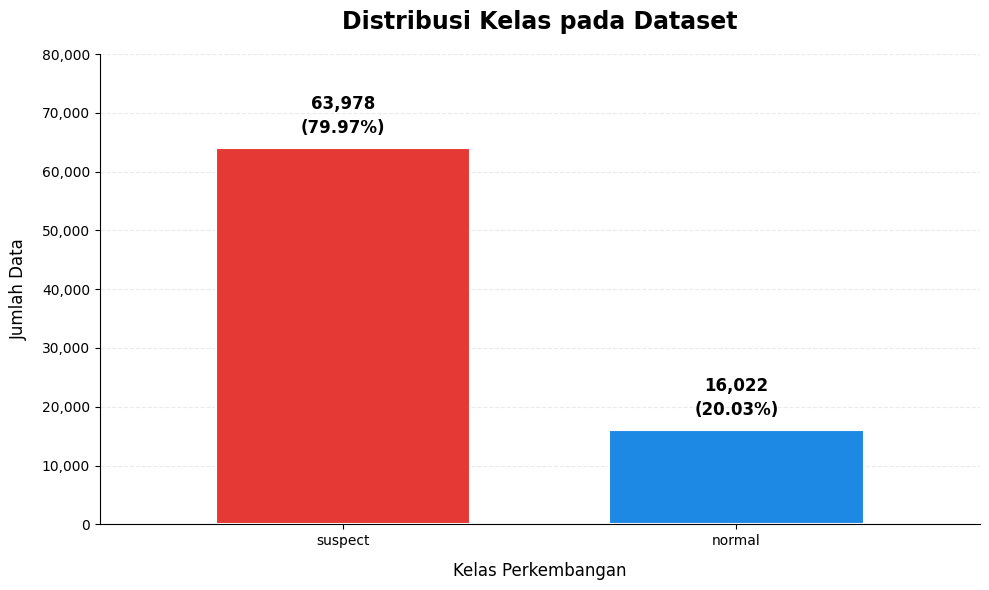

In [11]:
# Menggunakan hasil perhitungan sebelumnya
counts = target_counts
percentages = target_percentage.reindex(counts.index)

# Warna
color_map = {
    "suspect": "#E53935", 
    "normal": "#1E88E5"\
}
colors = [color_map.get(str(label).lower(), "#6482AD") for label in counts.index]

# Membuat visualisasi
fig, ax = plt.subplots(figsize=(10, 6))

# Mengatur posisi batang agar lebih berdekatan
x_positions = [0, 0.65]

bars = ax.bar(
    x_positions,
    counts.values,
    color=colors,
    width=0.42,
    edgecolor="white",
    linewidth=1.5
)

ax.set_xticks(x_positions)
ax.set_xticklabels(counts.index.astype(str))

# Label jumlah dan persentase di atas setiap batang
for bar, count, percentage in zip(
    bars, counts.values, percentages.values
):
    ax.annotate(
        f"{count:,}\n({percentage:.2f}%)",
        xy=(bar.get_x() + bar.get_width() / 2, bar.get_height()),
        xytext=(0, 8),
        textcoords="offset points",
        ha="center",
        va="bottom",
        fontsize=12,
        fontweight="bold",
        linespacing=1.4
    )

# Judul dan label sumbu
ax.set_title(
    "Distribusi Kelas pada Dataset",
    fontsize=17,
    fontweight="bold",
    pad=18
)
ax.set_xlabel("Kelas Perkembangan", fontsize=12, labelpad=10)
ax.set_ylabel("Jumlah Data", fontsize=12, labelpad=10)

# Sumbu Y dari 0 sampai 80.000
ax.set_ylim(0, 80000)
ax.set_yticks(range(0, 80001, 10000))
ax.yaxis.set_major_formatter(
    FuncFormatter(lambda value, _: f"{value:,.0f}")
)

# Merapikan tampilan
ax.grid(axis="y", linestyle="--", alpha=0.25)
ax.set_axisbelow(True)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.margins(x=0.18)

plt.tight_layout()
plt.show()


## Cek kategori fitur

In [12]:
categorical_columns = [
    "gross_motor",
    "fine_motor_adaptive",
    "language",
    "personal_social"
]

for col in categorical_columns:
    print(f"\n===== {col} =====")
    print(df[col].value_counts(dropna=False))


===== gross_motor =====
gross_motor
delayed     20094
normal      20069
caution     19935
advanced    19902
Name: count, dtype: int64

===== fine_motor_adaptive =====
fine_motor_adaptive
normal      20089
delayed     20032
caution     19950
advanced    19929
Name: count, dtype: int64

===== language =====
language
delayed     20269
caution     19998
normal      19892
advanced    19841
Name: count, dtype: int64

===== personal_social =====
personal_social
normal      20039
advanced    20016
caution     19985
delayed     19960
Name: count, dtype: int64


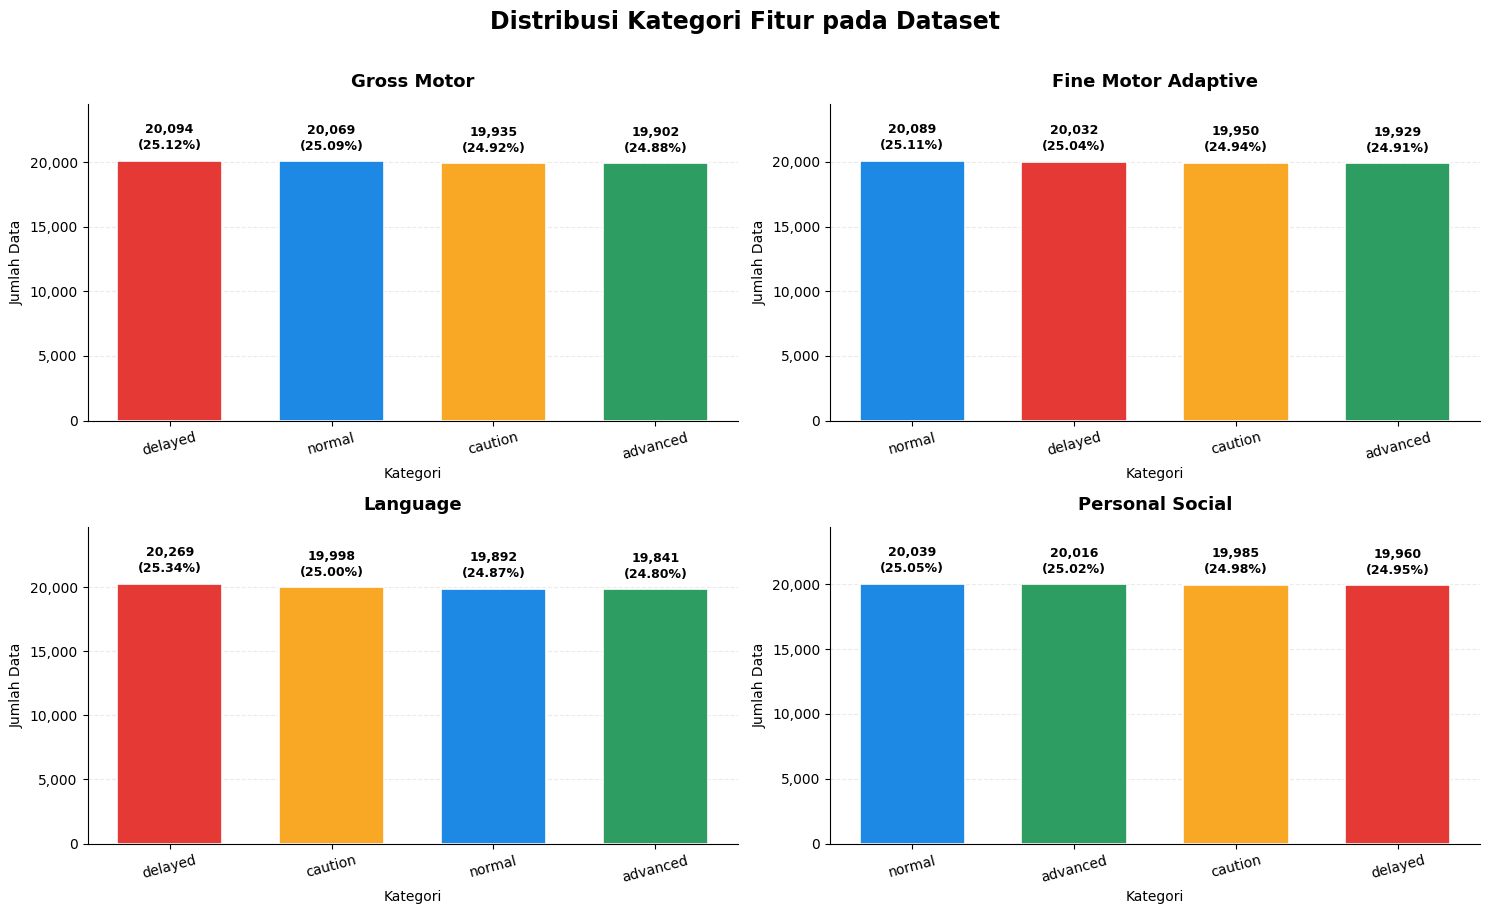

In [13]:

import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
import math
import pandas as pd

# Menggunakan daftar fitur kategorikal yang sudah dibuat sebelumnya
n_cols = 2
n_rows = math.ceil(len(categorical_columns) / n_cols)

fig, axes = plt.subplots(
    n_rows, n_cols,
    figsize=(15, 4.5 * n_rows)
)
axes = axes.flatten()

# Warna konsisten untuk kategori yang umum digunakan
color_map = {
    "suspect": "#E53935",
    "normal": "#1E88E5",
    "delayed": "#E53935",
    "caution": "#F9A825",
    "advanced": "#2E9D62"
}

for i, col in enumerate(categorical_columns):
    ax = axes[i]

    # Menghitung jumlah kategori sekali, lalu persentasenya dari jumlah tersebut
    counts = df[col].value_counts(dropna=False)
    percentages = counts / counts.sum() * 100

    labels = [
        "Missing" if pd.isna(value) else str(value)
        for value in counts.index
    ]

    colors = [
        color_map.get(label.lower(), "#6482AD")
        for label in labels
    ]

    bars = ax.bar(
        labels,
        counts.values,
        color=colors,
        width=0.65,
        edgecolor="white",
        linewidth=1.2
    )

    # Jumlah di atas, persentase di bawahnya
    for bar, count, percentage in zip(
        bars, counts.values, percentages.values
    ):
        ax.annotate(
            f"{count:,}\n({percentage:.2f}%)",
            xy=(bar.get_x() + bar.get_width() / 2, bar.get_height()),
            xytext=(0, 6),
            textcoords="offset points",
            ha="center",
            va="bottom",
            fontsize=9,
            fontweight="bold",
            linespacing=1.3
        )

    ax.set_title(
        col.replace("_", " ").title(),
        fontsize=13,
        fontweight="bold",
        pad=12
    )
    ax.set_xlabel("Kategori", fontsize=10)
    ax.set_ylabel("Jumlah Data", fontsize=10)

    ax.yaxis.set_major_formatter(
        FuncFormatter(lambda value, _: f"{value:,.0f}")
    )

    ax.set_ylim(0, counts.max() * 1.22)
    ax.grid(axis="y", linestyle="--", alpha=0.25)
    ax.set_axisbelow(True)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.tick_params(axis="x", rotation=15)

# Sembunyikan subplot yang tidak digunakan
for j in range(len(categorical_columns), len(axes)):
    axes[j].set_visible(False)

fig.suptitle(
    "Distribusi Kategori Fitur pada Dataset",
    fontsize=17,
    fontweight="bold",
    y=1.01
)

plt.tight_layout()
plt.show()


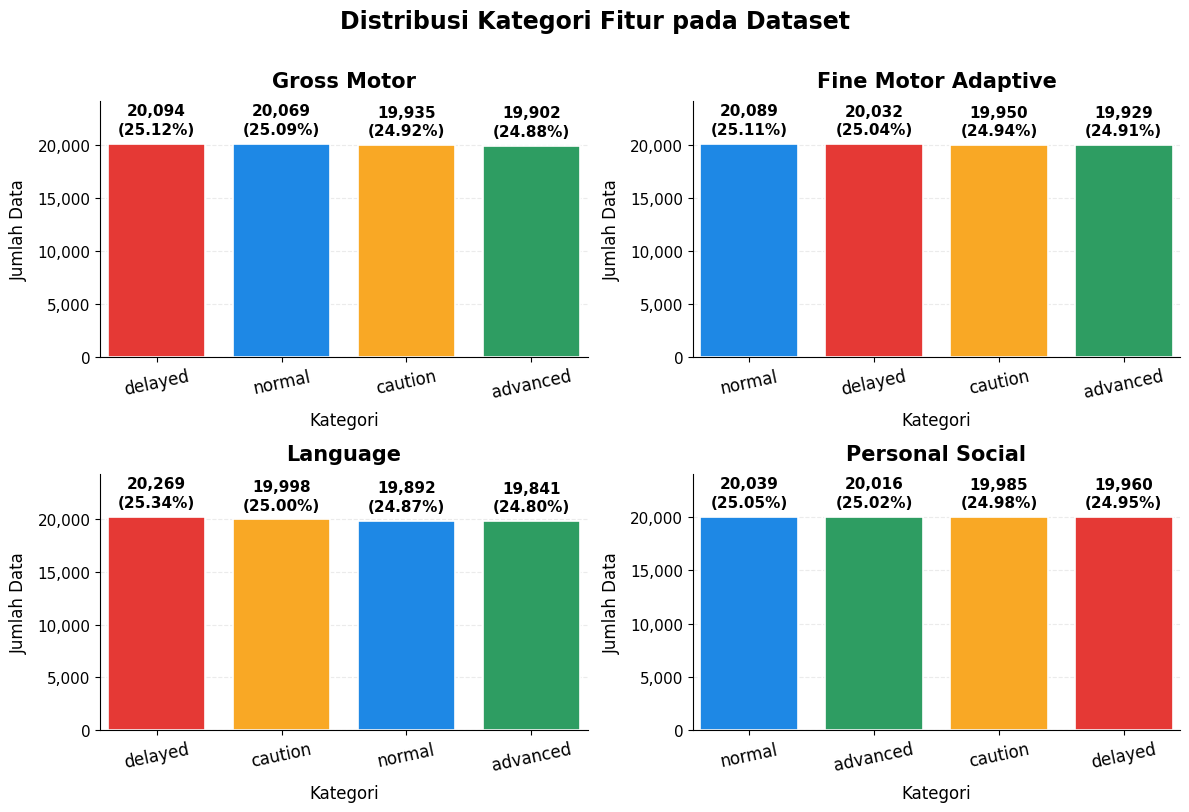

In [14]:

import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
import math
import pandas as pd

# Tata letak: 2 kolom, ukuran gambar lebih ringkas
n_cols = 2
n_rows = math.ceil(len(categorical_columns) / n_cols)

fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(12, 4 * n_rows)
)
axes = axes.flatten()

# Warna kategori
color_map = {
    "suspect": "#E53935",
    "normal": "#1E88E5",
    "delayed": "#E53935",
    "caution": "#F9A825",
    "advanced": "#2E9D62"
}

for i, col in enumerate(categorical_columns):
    ax = axes[i]

    # Jumlah dan persentase kategori
    counts = df[col].value_counts(dropna=False)
    percentages = counts / counts.sum() * 100

    labels = [
        "Missing" if pd.isna(value) else str(value)
        for value in counts.index
    ]

    colors = [
        color_map.get(label.lower(), "#6482AD")
        for label in labels
    ]

    # Posisi batang dibuat lebih rapat
    x_positions = range(len(labels))

    bars = ax.bar(
        x_positions,
        counts.values,
        color=colors,
        width=0.78,
        edgecolor="white",
        linewidth=1.2
    )

    ax.set_xticks(list(x_positions))
    ax.set_xticklabels(labels, fontsize=12, rotation=12)

    # Label jumlah dan persentase di atas batang
    for bar, count, percentage in zip(
        bars, counts.values, percentages.values
    ):
        ax.annotate(
            f"{count:,}\n({percentage:.2f}%)",
            xy=(
                bar.get_x() + bar.get_width() / 2,
                bar.get_height()
            ),
            xytext=(0, 5),
            textcoords="offset points",
            ha="center",
            va="bottom",
            fontsize=11,
            fontweight="bold",
            linespacing=1.3
        )

    ax.set_title(
        col.replace("_", " ").title(),
        fontsize=15,
        fontweight="bold",
        pad=10
    )

    ax.set_xlabel("Kategori", fontsize=12, labelpad=7)
    ax.set_ylabel("Jumlah Data", fontsize=12, labelpad=7)

    ax.yaxis.set_major_formatter(
        FuncFormatter(lambda value, _: f"{value:,.0f}")
    )
    ax.tick_params(axis="y", labelsize=11)

    # Ruang untuk label di atas batang
    ax.set_ylim(0, counts.max() * 1.20)

    # Tampilan grafik
    ax.grid(axis="y", linestyle="--", alpha=0.25)
    ax.set_axisbelow(True)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    # Mempersempit ruang kosong kiri dan kanan
    ax.set_xlim(-0.45, len(labels) - 0.55)

# Sembunyikan subplot yang tidak digunakan
for j in range(len(categorical_columns), len(axes)):
    axes[j].set_visible(False)

fig.suptitle(
    "Distribusi Kategori Fitur pada Dataset",
    fontsize=17,
    fontweight="bold",
    y=1.01
)

plt.tight_layout()

# Simpan dengan resolusi tinggi untuk Word
plt.savefig(
    "distribusi_kategori_fitur.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()


## Cek fitur numerik

In [15]:
numeric_columns = [
    "weight",
    "height",
    "age"
]

display(df[numeric_columns].describe())

,weight,height,age
count,80000.000000,80000.000000,80000.000000
mean,11.502838,84.885775,2.497537
std,5.186948,20.480889,1.712536
min,3.000000,50.000000,0.000000
25%,7.000000,67.000000,1.000000
50%,12.000000,85.000000,3.000000
75%,16.000000,103.000000,4.000000
max,20.000000,120.000000,5.000000


In [16]:
for col in numeric_columns:
    print(f"\n===== {col} =====")
    print("Minimum :", df[col].min())
    print("Maximum :", df[col].max())


===== weight =====
Minimum : 3
Maximum : 20

===== height =====
Minimum : 50
Maximum : 120

===== age =====
Minimum : 0
Maximum : 5


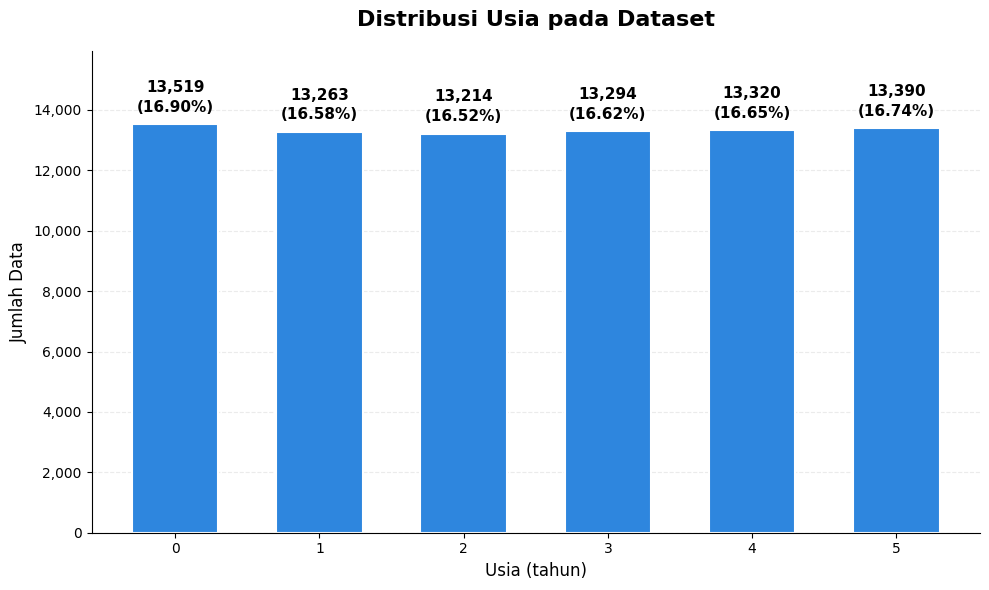

In [17]:

import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

# Mengambil data usia yang tersedia
age_data = df["age"].dropna()

# Menghitung jumlah dan persentase setiap kelompok usia
age_counts = age_data.value_counts().sort_index()
age_percentages = age_counts / age_counts.sum() * 100

# Membuat visualisasi
fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.bar(
    age_counts.index.astype(int).astype(str),
    age_counts.values,
    color="#2E86DE",
    edgecolor="white",
    linewidth=1.5,
    width=0.6
)

# Menampilkan jumlah di atas dan persentase di bawahnya
for bar, count, percentage in zip(
    bars, age_counts.values, age_percentages.values
):
    ax.annotate(
        f"{count:,}\n({percentage:.2f}%)",
        xy=(bar.get_x() + bar.get_width() / 2, bar.get_height()),
        xytext=(0, 7),
        textcoords="offset points",
        ha="center",
        va="bottom",
        fontsize=11,
        fontweight="bold",
        linespacing=1.4
    )

# Judul dan label
ax.set_title(
    "Distribusi Usia pada Dataset",
    fontsize=16,
    fontweight="bold",
    pad=18
)
ax.set_xlabel("Usia (tahun)", fontsize=12)
ax.set_ylabel("Jumlah Data", fontsize=12)

ax.yaxis.set_major_formatter(
    FuncFormatter(lambda value, _: f"{value:,.0f}")
)

# Tata letak agar label mudah dibaca
ax.set_ylim(0, age_counts.max() * 1.18)
ax.grid(axis="y", linestyle="--", alpha=0.25)
ax.set_axisbelow(True)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()


## Audit akhir

In [18]:
print("Shape dataset:", df.shape)

print("\nKolom dataset:")
for i, col in enumerate(df.columns, start=1):
    print(f"{i}. {col}")

print("\n5 data pertama:")
display(df.head())

Shape dataset: (80000, 8)

Kolom dataset:
1. weight
2. height
3. age
4. gross_motor
5. fine_motor_adaptive
6. language
7. personal_social
8. dev_status

5 data pertama:


,weight,height,age,gross_motor,fine_motor_adaptive,language,personal_social,dev_status
0,16,113,1,delayed,advanced,normal,delayed,suspect
1,7,54,3,advanced,normal,caution,caution,suspect
2,17,106,1,delayed,normal,normal,normal,suspect
3,11,114,5,normal,normal,delayed,advanced,suspect
4,20,54,5,caution,advanced,delayed,delayed,suspect
